# Sirroz bemorlari omon qolish prognozi (Multi-class)
**Maqsad:** `Status_C`, `Status_CL`, `Status_D` ehtimolliklarini bashorat qilish. **Metrika:** multi-class log-loss.

Tarkib:
1) Yuklash
2) EDA
3) Feature engineering
4) CV: LightGBM, XGBoost, CatBoost
5) Baholash grafiklari (log-loss, ROC OvR, confusion matrix, kalibrovka, importance)
6) Blend vaznlarini optimallashtirish va `submission.csv`

In [1]:
!pip -q install lightgbm xgboost catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.2 MB/s eta 0:00:00


In [2]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.optimize import minimize
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import label_binarize
from sklearn.calibration import calibration_curve
from sklearn.metrics import (log_loss, roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
import lightgbm as lgb, xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
CLASSES = ['C', 'CL', 'D']
# submission ustunlari: Status_C, Status_CL, Status_D

## 1. Ma'lumotlarni yuklash

In [3]:
def find(name):
    base = name[:-4]
    for cand in (name, f'{base}_1.csv'):
        if os.path.exists(cand):
            return cand
    return None

names = ['train.csv', 'test.csv', 'sample_submission.csv']
if not all(find(n) for n in names):
    from google.colab import files
    files.upload()

train = pd.read_csv(find('train.csv'))
test = pd.read_csv(find('test.csv'))
sub = pd.read_csv(find('sample_submission.csv'))
print('train:', train.shape, '| test:', test.shape)
print('Submission ustunlari:', list(sub.columns))
train.head()

train: (15000, 20) | test: (10000, 19)
Submission ustunlari: ['id', 'Status_C', 'Status_CL', 'Status_D']


,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Status
0,0,2178.0,D-penicillamine,16374.0,F,N,N,N,N,0.5,263.0,3.20,43.0,1110.0,106.95,67.0,430.0,9.6,3.0,C
1,1,2644.0,D-penicillamine,17774.0,F,N,N,N,N,0.8,280.0,3.60,22.0,678.0,62.00,80.0,427.0,13.0,3.0,C
2,2,3069.0,Placebo,17844.0,F,N,N,N,N,1.1,408.0,4.40,54.0,2108.0,142.60,137.0,203.0,10.6,3.0,C
3,3,2216.0,Placebo,19221.0,F,N,Y,Y,N,0.8,252.0,3.70,36.0,843.0,55.80,56.0,336.0,9.6,4.0,C
4,4,2256.0,Placebo,21600.0,F,N,N,N,N,4.7,348.0,3.06,464.0,961.0,120.90,146.0,298.0,11.0,2.0,D


## 2. EDA

In [4]:
print(train.Status.value_counts())
# Eslatma: train'da sinf 'Y' bilan 1 ta qator bor — bu shovqin (musobaqada faqat C, CL, D bor). O'chiramiz.
train = train[train.Status.isin(CLASSES)].reset_index(drop=True)
print('\nTozalangandan keyin:', train.shape)
display(train.describe().T)
print('Dublikatlar:', train.drop(columns='id').duplicated().sum())

Status
C     10053
D      4565
CL      381
Y         1
Name: count, dtype: int64

Tozalangandan keyin: (14999, 20)


,count,mean,std,min,25%,50%,75%,max
id,14999.0,7499.080672,4330.111146,0.0,3749.50,7499.00,11248.50,14999.00
N_Days,14999.0,1971.577572,1333.661919,3.0,1095.00,1786.00,2635.00,38320.00
Age,14999.0,19298.574505,3797.693004,400.0,16658.00,19544.00,22347.00,129398.00
Bilirubin,14999.0,1.845516,2.674929,0.2,0.60,0.90,1.80,28.00
Cholesterol,6700.0,329.186582,180.332660,120.0,242.00,280.00,364.00,2078.00
Albumin,14999.0,3.526154,0.372227,0.5,3.29,3.58,3.77,4.64
Copper,8398.0,75.655037,74.831602,2.0,31.00,52.00,89.00,662.00
Alk_Phos,8487.0,1618.638954,1767.340219,3.4,720.00,1072.00,1664.00,13862.40
SGOT,8485.0,106.487595,57.208223,0.9,71.00,97.65,130.20,2653.00
Tryglicerides,6665.0,111.397247,55.054959,19.0,80.00,99.00,133.00,1669.00


Dublikatlar: 6


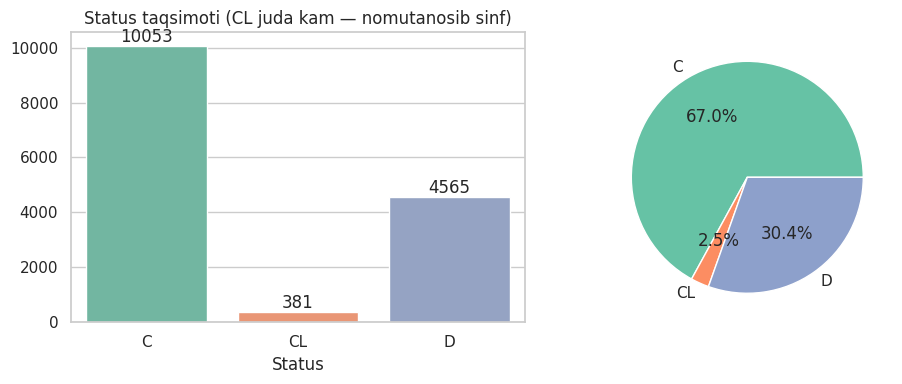

In [5]:
# Maqsad taqsimoti
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
vc = train.Status.value_counts().reindex(CLASSES)
sns.barplot(x=vc.index, y=vc.values, ax=ax[0], palette='Set2')
for i, v in enumerate(vc.values): ax[0].text(i, v, str(v), ha='center', va='bottom')
ax[0].set_title('Status taqsimoti (CL juda kam — nomutanosib sinf)')
ax[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%', colors=sns.color_palette('Set2'))
plt.tight_layout(); plt.show()

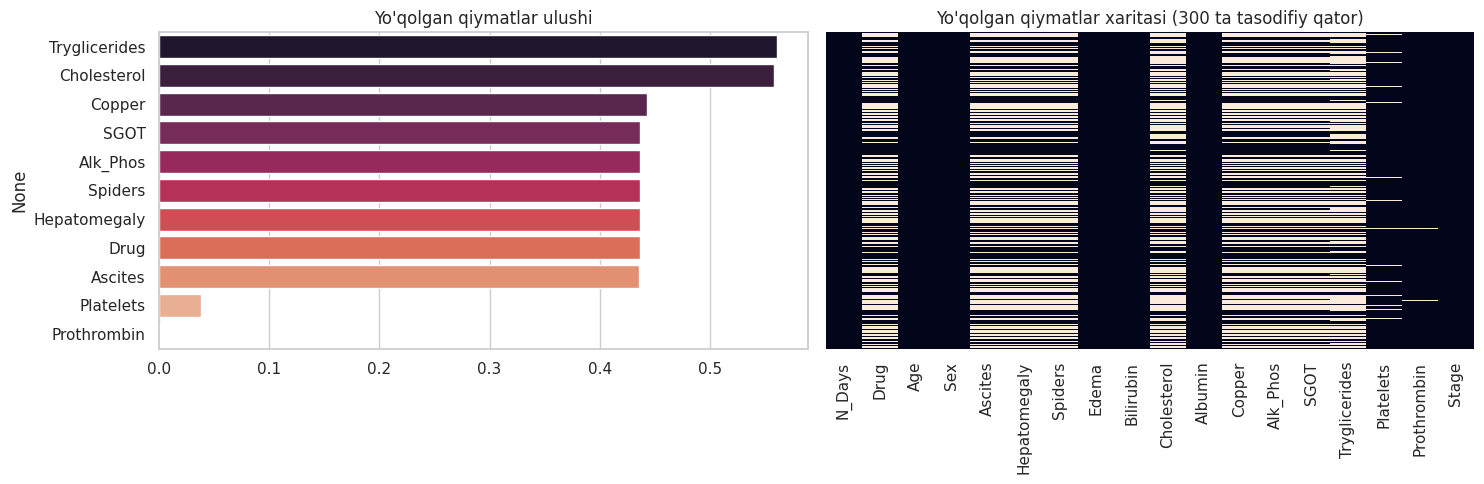

Status         C     CL      D
n_missing                     
False      0.675  0.026  0.298
True       0.664  0.024  0.312


In [6]:
# Yo'qolgan qiymatlar
miss = pd.concat([train.drop(columns='Status'), test]).isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=miss.values, y=miss.index, ax=ax[0], palette='rocket'); ax[0].set_title('Yo\'qolgan qiymatlar ulushi')
sns.heatmap(train.drop(columns=['id', 'Status']).sample(300, random_state=SEED).isna(), cbar=False, ax=ax[1], yticklabels=False)
ax[1].set_title('Yo\'qolgan qiymatlar xaritasi (300 ta tasodifiy qator)')
plt.tight_layout(); plt.show()

# Yo'qolgan qiymatlar soni va Status
tmp = train.copy(); tmp['n_missing'] = tmp.drop(columns='Status').isna().sum(axis=1)
print(pd.crosstab(tmp.n_missing > 3, tmp.Status, normalize='index').round(3))

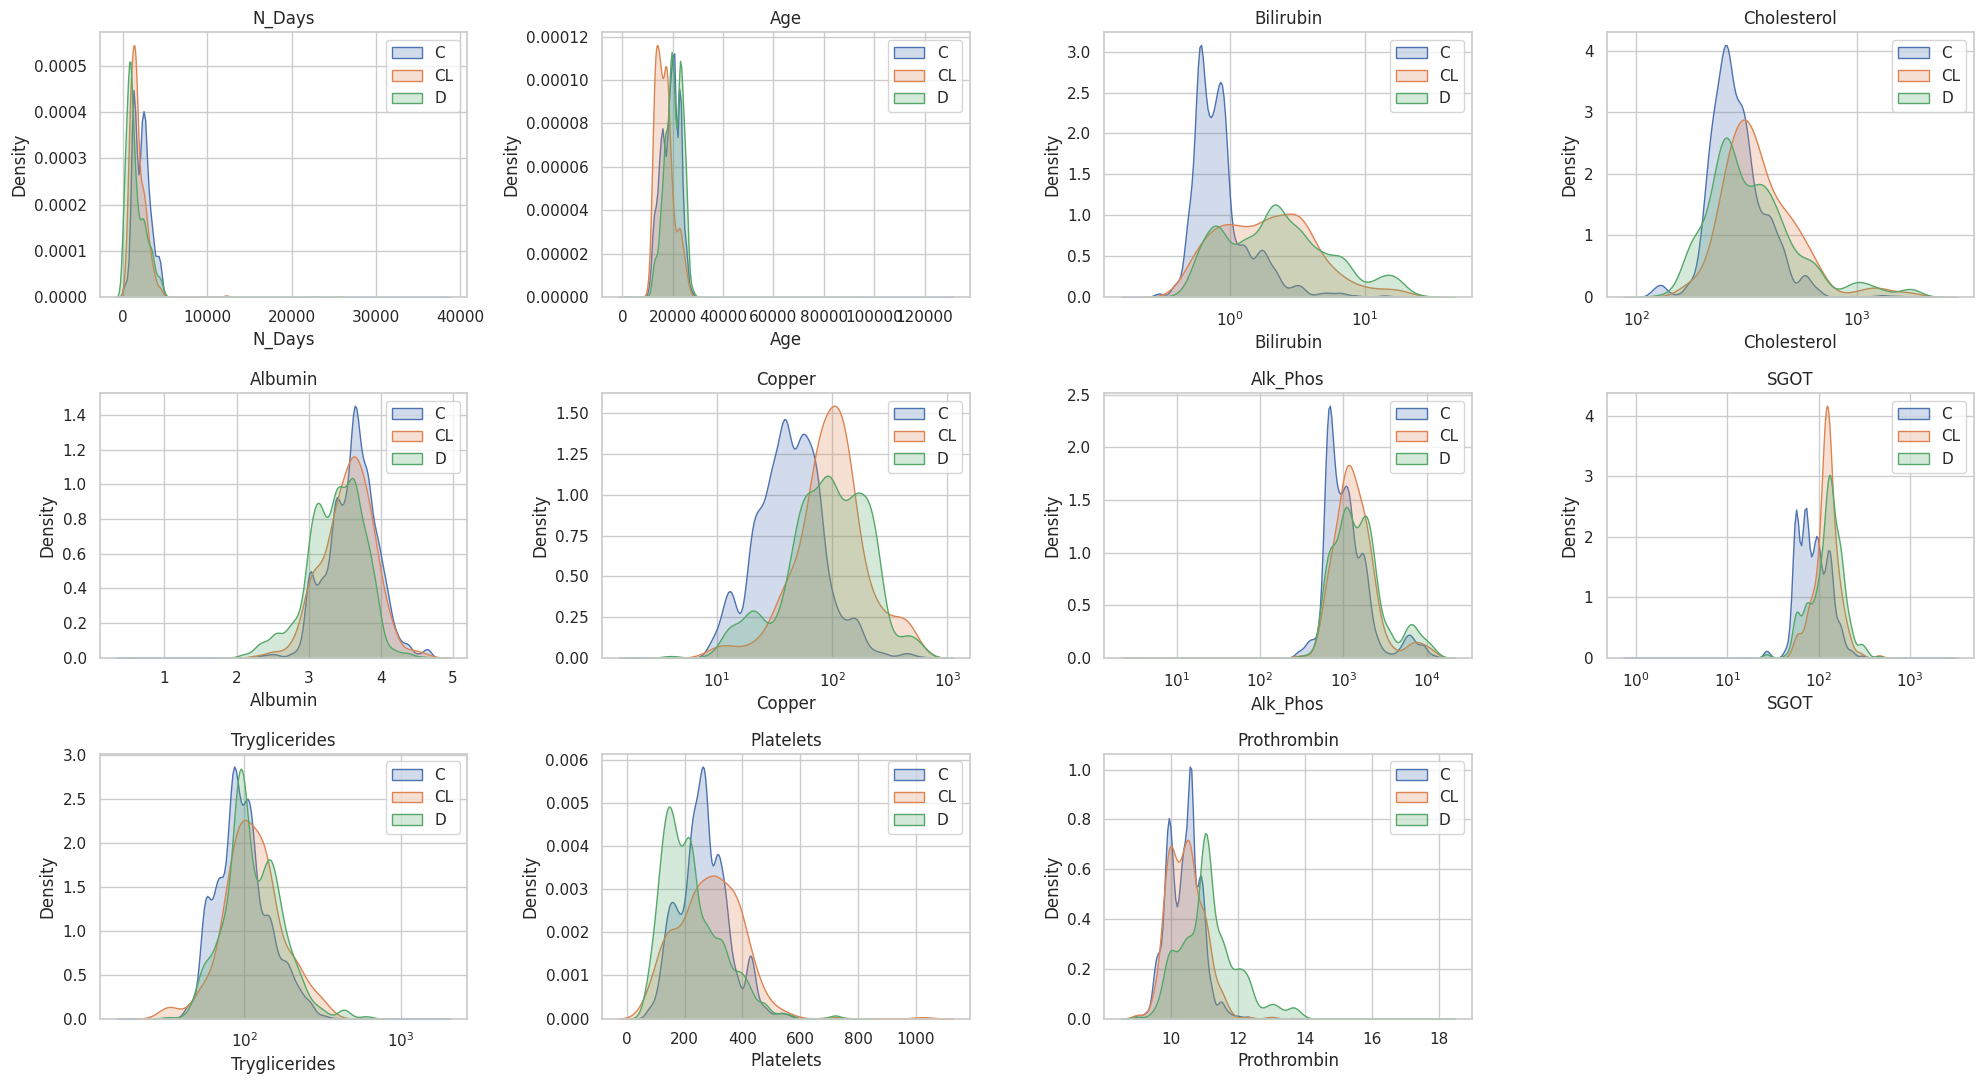

In [7]:
num_cols = ['N_Days', 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos',
            'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, c in zip(axes.ravel(), num_cols):
    d = train[[c, 'Status']].dropna()
    for s in CLASSES:
        sns.kdeplot(d.loc[d.Status == s, c], ax=ax, label=s, fill=True, alpha=.25, common_norm=False,
                    log_scale=c in ['Bilirubin', 'Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides'])
    ax.set_title(c); ax.legend()
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

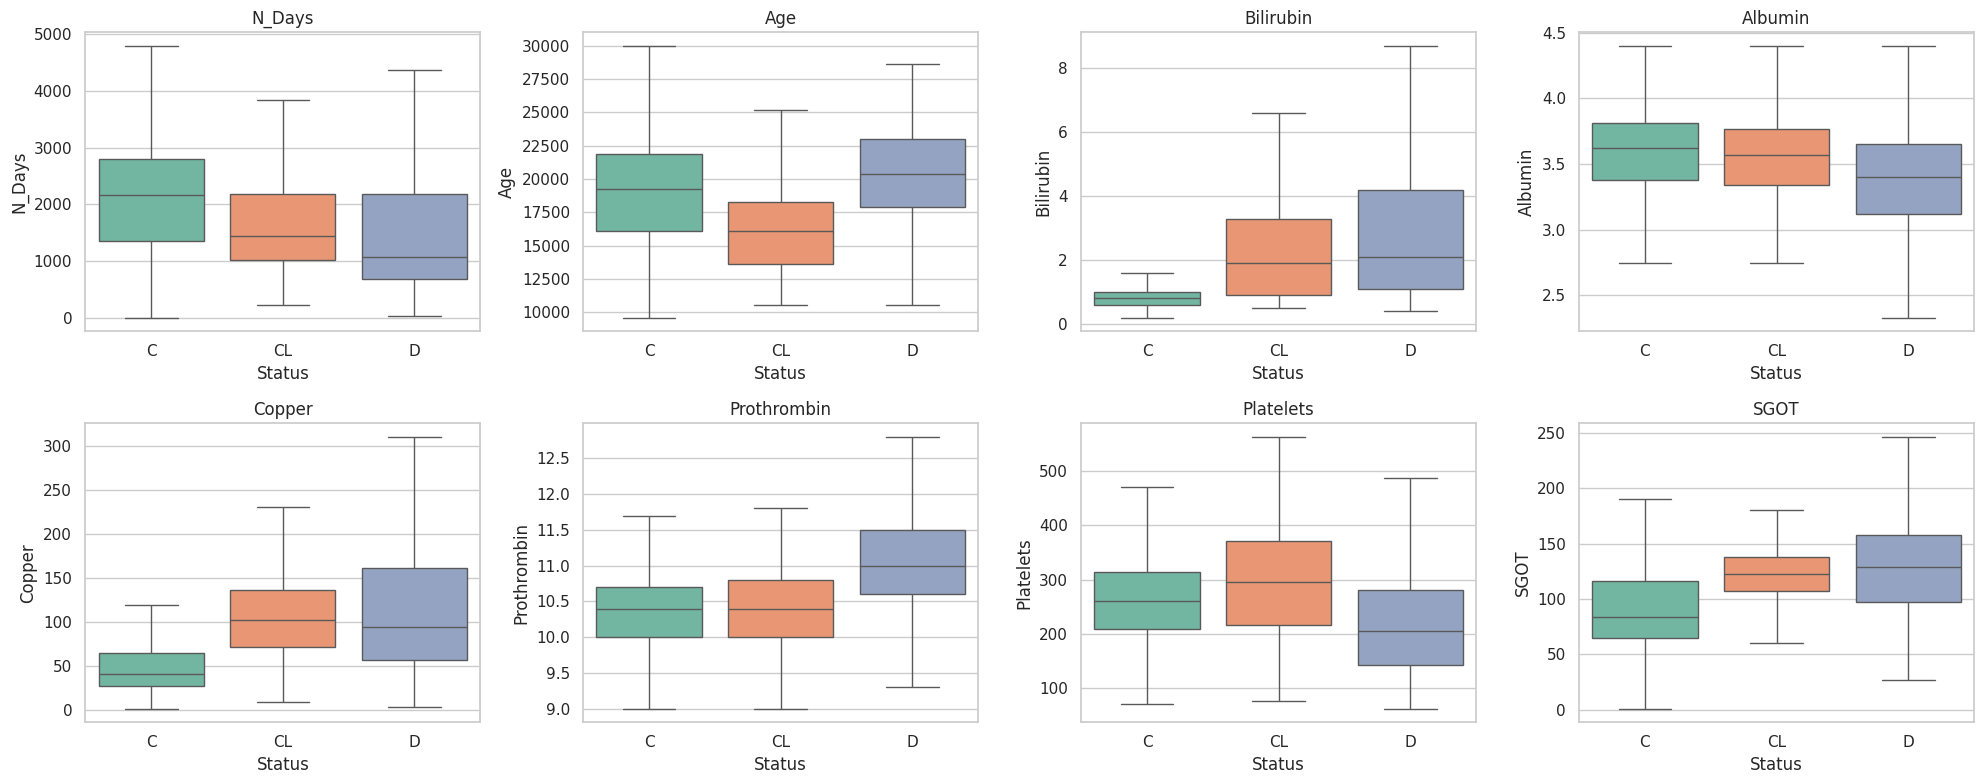

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), ['N_Days', 'Age', 'Bilirubin', 'Albumin', 'Copper', 'Prothrombin', 'Platelets', 'SGOT']):
    sns.boxplot(data=train, x='Status', y=c, order=CLASSES, ax=ax, palette='Set2', showfliers=False)
    ax.set_title(c)
plt.tight_layout(); plt.show()

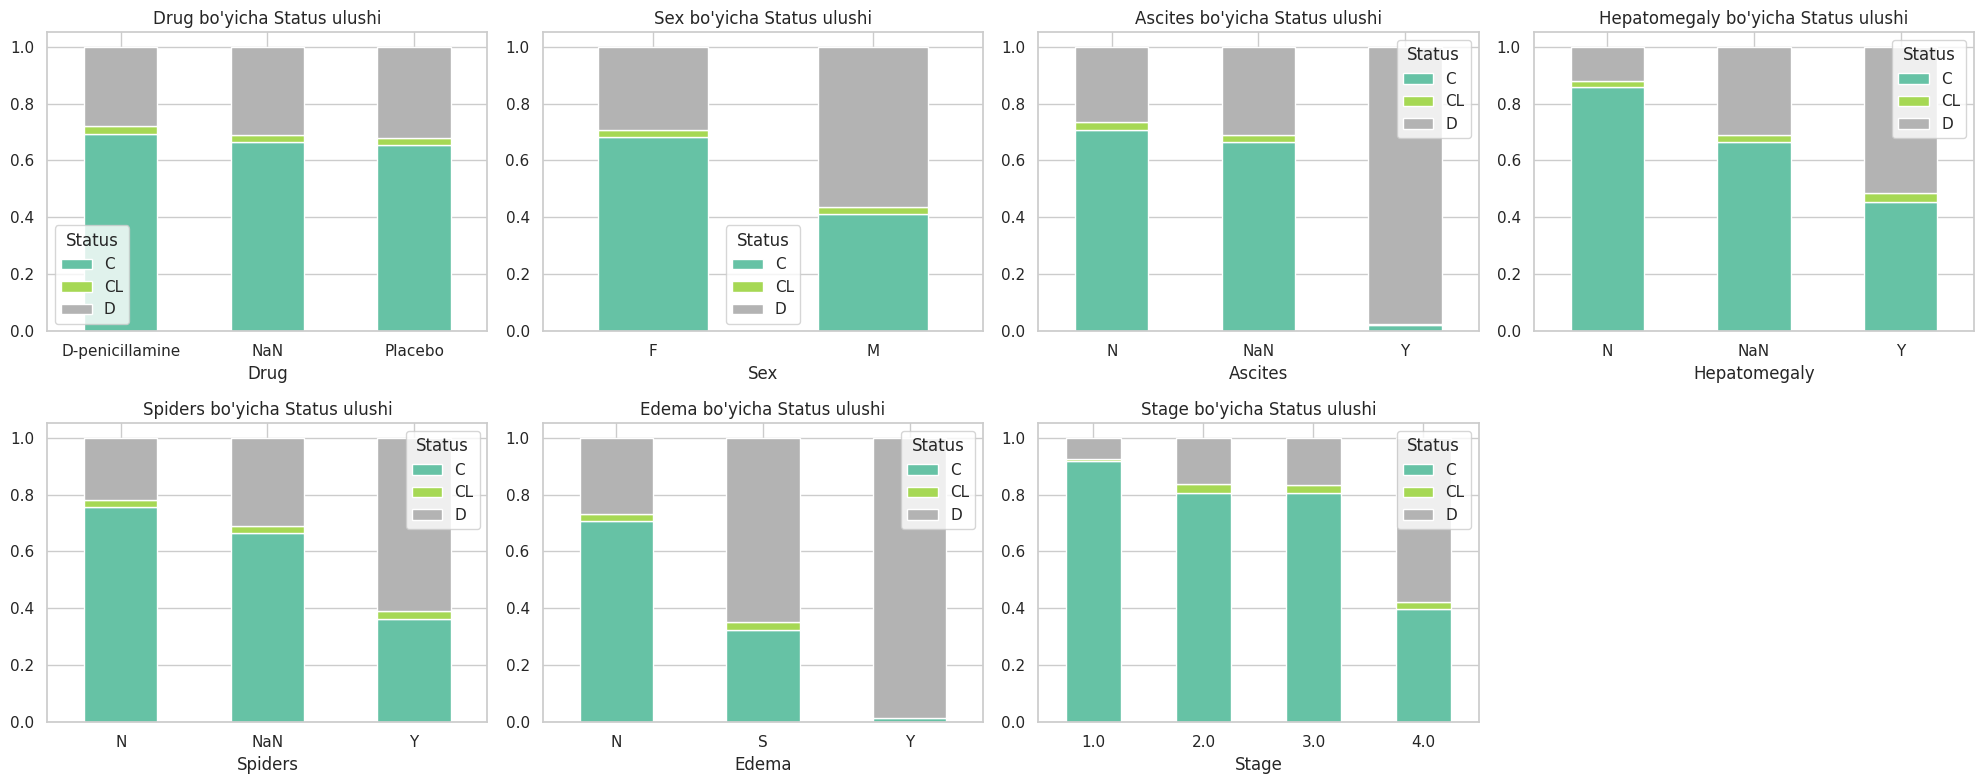

In [9]:
# Kategorik o'zgaruvchilar: Status ulushi (NaN ham alohida toifa)
cat_cols = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema', 'Stage']
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.ravel(), cat_cols):
    ct = pd.crosstab(train[c].fillna('NaN'), train.Status, normalize='index')[CLASSES]
    ct.plot(kind='bar', stacked=True, ax=ax, colormap='Set2', rot=0)
    ax.set_title(f'{c} bo\'yicha Status ulushi'); ax.set_ylabel('')
axes.ravel()[-1].axis('off')
plt.tight_layout(); plt.show()

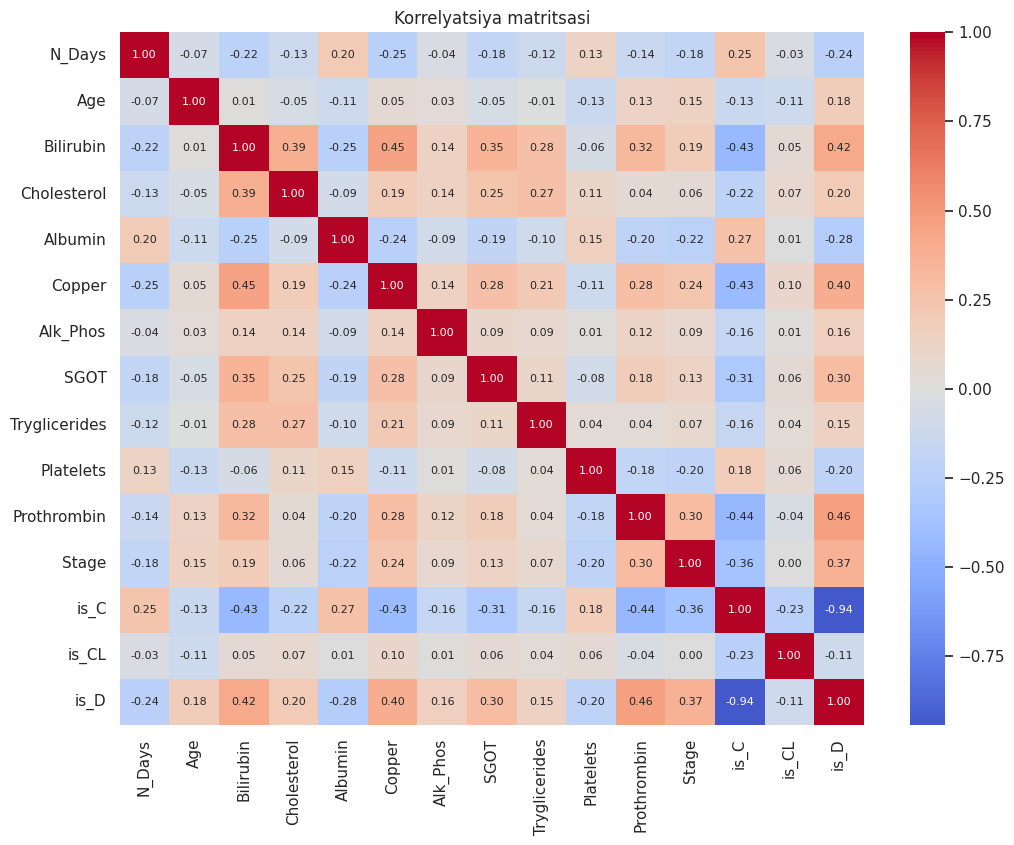

In [10]:
# Korrelyatsiya
cdf = train[num_cols + ['Stage']].copy()
for s in CLASSES: cdf['is_' + s] = (train.Status == s).astype(int)
plt.figure(figsize=(12, 9))
sns.heatmap(cdf.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Korrelyatsiya matritsasi'); plt.show()

## 3. Feature engineering

In [11]:
def make_features(tr, te):
    n = len(tr)
    df = pd.concat([tr.drop(columns='Status'), te], ignore_index=True)
    feats = df.drop(columns='id').copy()

    # Kategoriyalarni kodlash (NaN -> -1: yo'qolgan qiymatning o'zi signal bo'lishi mumkin)
    for c in ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders']:
        feats[c] = feats[c].map({'N': 0, 'Y': 1, 'F': 0, 'M': 1, 'Placebo': 0, 'D-penicillamine': 1}).fillna(-1)
    feats['Edema'] = feats.Edema.map({'N': 0, 'S': 1, 'Y': 2})

    lab = ['Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin']
    feats['n_missing'] = df[lab + ['Drug', 'Ascites', 'Hepatomegaly', 'Spiders']].isna().sum(axis=1)
    feats['Age_years'] = feats.Age / 365.25
    feats['N_Years'] = feats.N_Days / 365.25
    feats['Age_at_end'] = (feats.Age + feats.N_Days) / 365.25
    for c in ['Bilirubin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Cholesterol']:
        feats['log_' + c] = np.log1p(feats[c])
    feats['Bili_Alb'] = feats.Bilirubin / feats.Albumin
    feats['Bili_x_Prothr'] = feats.Bilirubin * feats.Prothrombin
    feats['Copper_Alb'] = feats.Copper / feats.Albumin
    feats['SGOT_Plt'] = feats.SGOT / feats.Platelets
    feats['Symptoms'] = feats[['Ascites', 'Hepatomegaly', 'Spiders']].clip(lower=0).sum(axis=1) + feats.Edema
    feats['Stage_Bili'] = feats.Stage * feats.Bilirubin
    feats['Days_per_Stage'] = feats.N_Days / feats.Stage
    return feats.iloc[:n].reset_index(drop=True), feats.iloc[n:].reset_index(drop=True)

X, X_test = make_features(train, test)
y = train.Status.map({c: i for i, c in enumerate(CLASSES)}).values
print(X.shape, X_test.shape)

(14999, 35) (10000, 35)


## 4. Cross-validation (5-fold, stratified)

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X, y))

def run_cv(name, fit_predict):
    oof = np.zeros((len(X), 3)); pred = np.zeros((len(X_test), 3)); models = []
    for i, (a, b) in enumerate(folds):
        m, p_val, p_te = fit_predict(X.iloc[a], y[a], X.iloc[b], y[b], X_test)
        oof[b] = p_val; pred += p_te / len(folds); models.append(m)
        print(f'[{name}] fold {i}: log-loss = {log_loss(y[b], p_val):.5f}')
    print(f'[{name}] OOF log-loss = {log_loss(y, oof):.5f}\n')
    return oof, pred, models

def fit_lgb(Xa, ya, Xb, yb, Xt):
    m = lgb.LGBMClassifier(objective='multiclass', num_class=3, learning_rate=0.03, num_leaves=15,
                           min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
                           reg_lambda=5, n_estimators=4000, random_state=SEED, verbose=-1)
    m.fit(Xa, ya, eval_set=[(Xb, yb)], eval_metric='multi_logloss',
          callbacks=[lgb.early_stopping(150, verbose=False)])
    return m, m.predict_proba(Xb), m.predict_proba(Xt)

def fit_xgb(Xa, ya, Xb, yb, Xt):
    m = xgb.XGBClassifier(objective='multi:softprob', n_estimators=4000, learning_rate=0.03, max_depth=4,
                          subsample=0.8, colsample_bytree=0.6, min_child_weight=3, reg_lambda=5,
                          eval_metric='mlogloss', early_stopping_rounds=150, random_state=SEED, tree_method='hist')
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    return m, m.predict_proba(Xb), m.predict_proba(Xt)

def fit_cat(Xa, ya, Xb, yb, Xt):
    m = CatBoostClassifier(loss_function='MultiClass', iterations=4000, learning_rate=0.06, depth=6,
                           l2_leaf_reg=5, early_stopping_rounds=150, random_seed=SEED, verbose=False)
    m.fit(Xa, ya, eval_set=(Xb, yb))
    return m, m.predict_proba(Xb), m.predict_proba(Xt)

oof_lgb, pred_lgb, models_lgb = run_cv('LightGBM', fit_lgb)
oof_xgb, pred_xgb, models_xgb = run_cv('XGBoost', fit_xgb)
oof_cat, pred_cat, models_cat = run_cv('CatBoost', fit_cat)

[LightGBM] fold 0: log-loss = 0.38861
[LightGBM] fold 1: log-loss = 0.36565
[LightGBM] fold 2: log-loss = 0.38136
[LightGBM] fold 3: log-loss = 0.37325
[LightGBM] fold 4: log-loss = 0.37299
[LightGBM] OOF log-loss = 0.37638

[XGBoost] fold 0: log-loss = 0.38570
[XGBoost] fold 1: log-loss = 0.36476
[XGBoost] fold 2: log-loss = 0.38073
[XGBoost] fold 3: log-loss = 0.37398
[XGBoost] fold 4: log-loss = 0.37188
[XGBoost] OOF log-loss = 0.37541

[CatBoost] fold 0: log-loss = 0.39473
[CatBoost] fold 1: log-loss = 0.37419
[CatBoost] fold 2: log-loss = 0.39002
[CatBoost] fold 3: log-loss = 0.38230
[CatBoost] fold 4: log-loss = 0.38482
[CatBoost] OOF log-loss = 0.38521



## 5. Blend vaznlarini optimallashtirish

In [13]:
EPS = 1e-15
def score(p, yt):
    p = np.clip(p, EPS, 1 - EPS); p = p / p.sum(axis=1, keepdims=True)
    return log_loss(yt, p)

oofs = [oof_lgb, oof_xgb, oof_cat]; preds = [pred_lgb, pred_xgb, pred_cat]

def blend(ws, arrs):
    ws = np.abs(ws) / np.abs(ws).sum()
    return sum(w * a for w, a in zip(ws, arrs))

res = minimize(lambda w: score(blend(w, oofs), y), x0=np.ones(3) / 3, method='Nelder-Mead')
w_opt = np.abs(res.x) / np.abs(res.x).sum()
oof_blend = blend(w_opt, oofs)
print('Vaznlar (LGB, XGB, CAT):', w_opt.round(3))
print('Blend OOF log-loss:', round(score(oof_blend, y), 5))

Vaznlar (LGB, XGB, CAT): [0.281 0.664 0.055]
Blend OOF log-loss: 0.37512


## 6. Baholash grafiklari

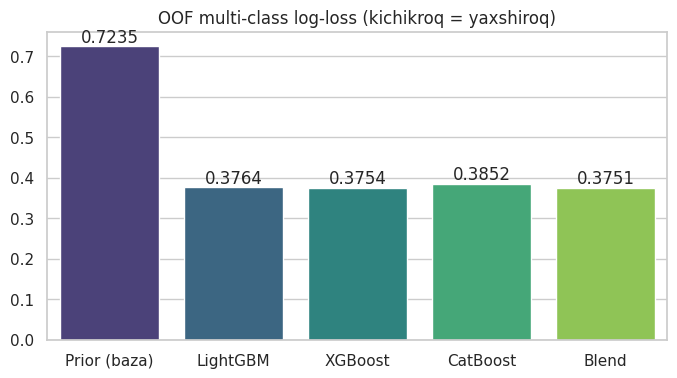

In [14]:
# Modellar log-loss taqqoslash
scores = {'LightGBM': score(oof_lgb, y), 'XGBoost': score(oof_xgb, y), 'CatBoost': score(oof_cat, y),
          'Blend': score(oof_blend, y)}
# Baza chizig'i: train'dagi sinf ulushlarini doimiy bashorat qilish
prior = np.tile(np.bincount(y) / len(y), (len(y), 1)); scores = {'Prior (baza)': score(prior, y), **scores}
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=list(scores.keys()), y=list(scores.values()), palette='viridis')
for p in ax.patches: ax.annotate(f'{p.get_height():.4f}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.title('OOF multi-class log-loss (kichikroq = yaxshiroq)'); plt.show()

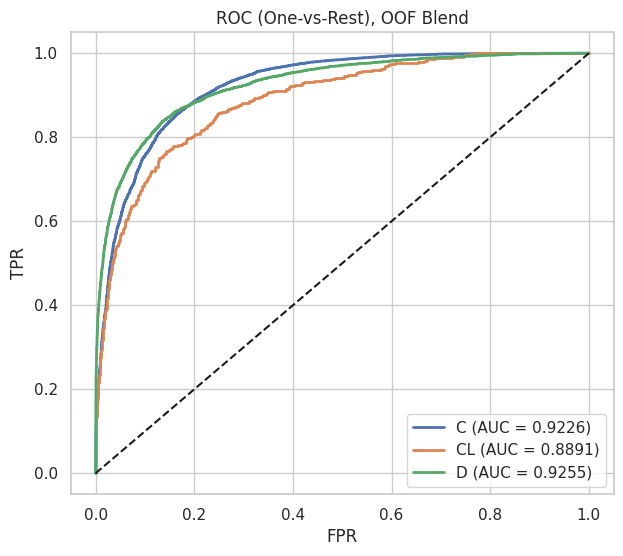

Macro OvR AUC: 0.9124


In [15]:
# ROC egri chiziqlari (One-vs-Rest) — Blend
Y = label_binarize(y, classes=[0, 1, 2])
plt.figure(figsize=(7, 6))
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(Y[:, k], oof_blend[:, k])
    plt.plot(fpr, tpr, lw=2, label=f'{c} (AUC = {roc_auc_score(Y[:, k], oof_blend[:, k]):.4f})')
plt.plot([0, 1], [0, 1], 'k--'); plt.legend(loc='lower right')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC (One-vs-Rest), OOF Blend'); plt.show()
print('Macro OvR AUC:', round(roc_auc_score(y, oof_blend, multi_class='ovr'), 4))

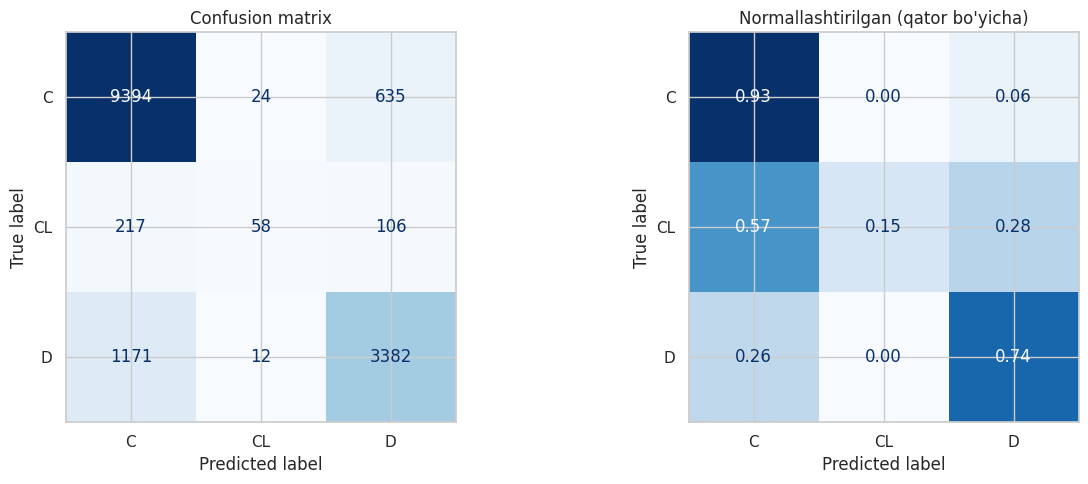

              precision    recall  f1-score   support

           C       0.87      0.93      0.90     10053
          CL       0.62      0.15      0.24       381
           D       0.82      0.74      0.78      4565

    accuracy                           0.86     14999
   macro avg       0.77      0.61      0.64     14999
weighted avg       0.85      0.86      0.85     14999



In [16]:
# Confusion matrix + hisobot
pred_lbl = oof_blend.argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y, pred_lbl), display_labels=CLASSES).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')
ConfusionMatrixDisplay(confusion_matrix(y, pred_lbl, normalize='true'), display_labels=CLASSES).plot(ax=ax[1], cmap='Blues', colorbar=False, values_format='.2f')
ax[1].set_title('Normallashtirilgan (qator bo\'yicha)')
plt.tight_layout(); plt.show()
print(classification_report(y, pred_lbl, target_names=CLASSES))

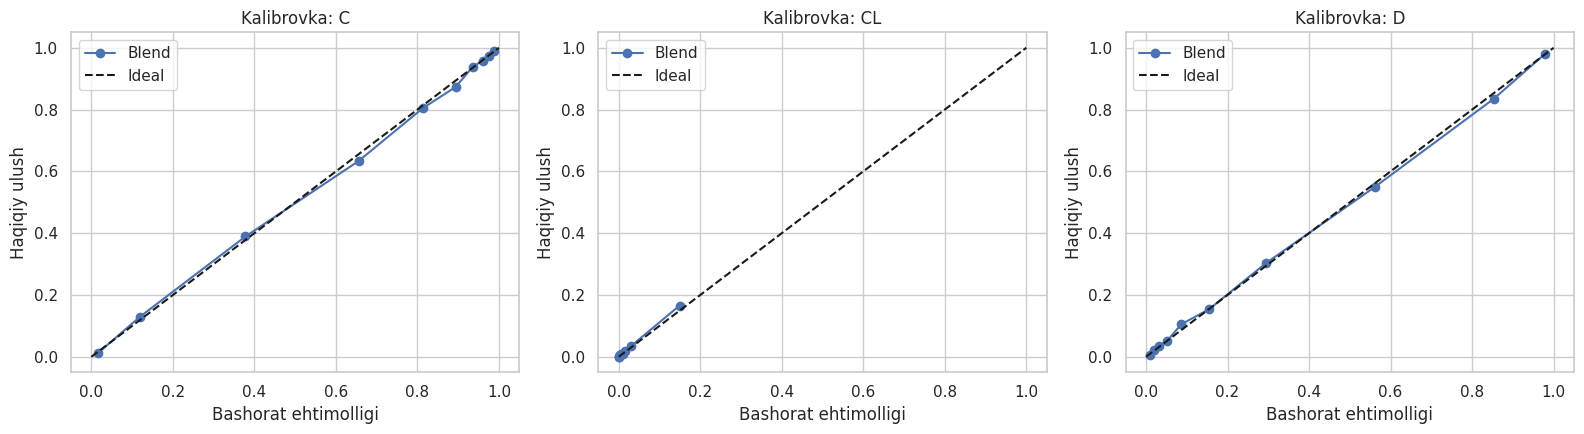

In [17]:
# Kalibrovka (reliability) egri chiziqlari
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for k, (ax, c) in enumerate(zip(axes, CLASSES)):
    fr, mp = calibration_curve(Y[:, k], oof_blend[:, k], n_bins=10, strategy='quantile')
    ax.plot(mp, fr, 'o-', label='Blend'); ax.plot([0, 1], [0, 1], 'k--', label='Ideal')
    ax.set_title(f'Kalibrovka: {c}'); ax.set_xlabel('Bashorat ehtimolligi'); ax.set_ylabel('Haqiqiy ulush'); ax.legend()
plt.tight_layout(); plt.show()

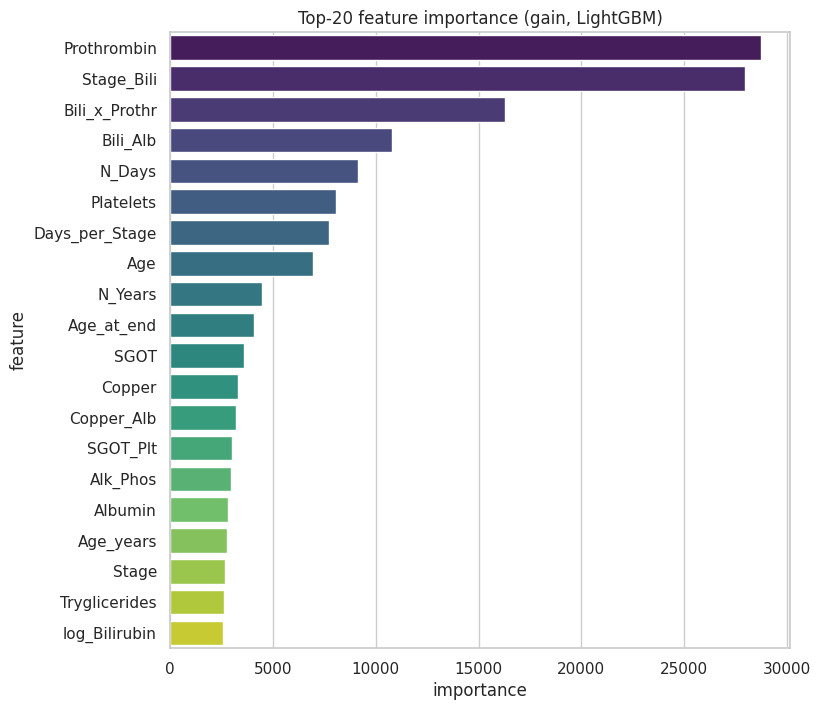

In [18]:
# Feature importance (LightGBM, gain)
imp = pd.DataFrame({'feature': X.columns,
                    'importance': np.mean([m.booster_.feature_importance('gain') for m in models_lgb], axis=0)})
imp = imp.sort_values('importance', ascending=False).head(20)
plt.figure(figsize=(8, 8)); sns.barplot(data=imp, x='importance', y='feature', palette='viridis')
plt.title('Top-20 feature importance (gain, LightGBM)'); plt.show()

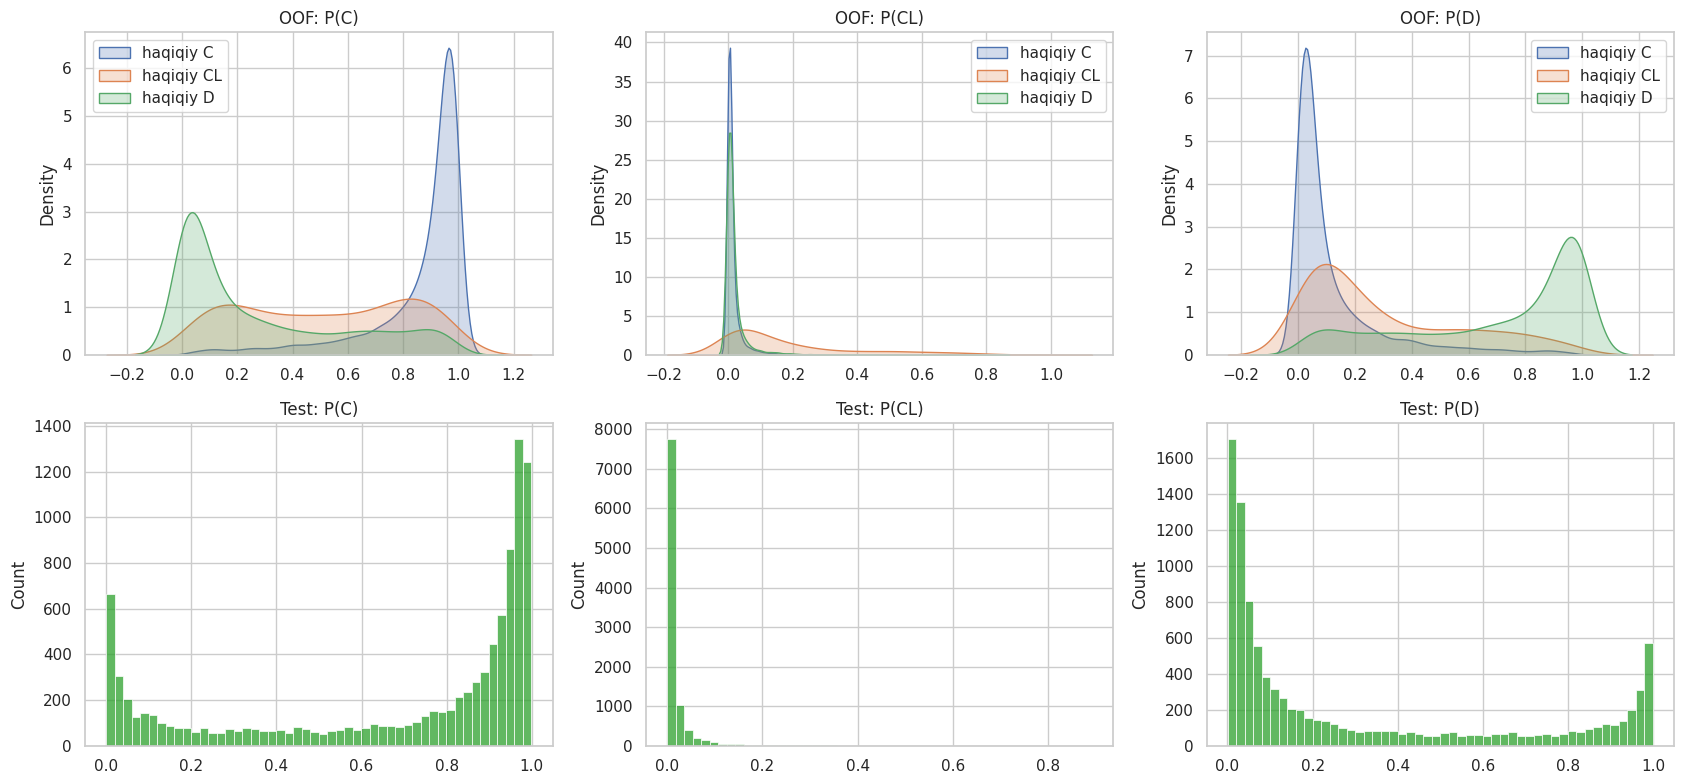

In [19]:
# Bashorat taqsimoti: har bir sinf uchun, OOF (haqiqiy label bo'yicha) va test
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for k, c in enumerate(CLASSES):
    for s in range(3):
        sns.kdeplot(oof_blend[y == s, k], ax=axes[0, k], label=f'haqiqiy {CLASSES[s]}', fill=True, alpha=.25, common_norm=False)
    axes[0, k].set_title(f'OOF: P({c})'); axes[0, k].legend()
test_blend = blend(w_opt, preds)
for k, c in enumerate(CLASSES):
    sns.histplot(test_blend[:, k], bins=50, ax=axes[1, k], color='tab:green'); axes[1, k].set_title(f'Test: P({c})')
plt.tight_layout(); plt.show()

## 7. Submission

In [20]:
final = np.clip(test_blend, 1e-15, 1 - 1e-15)
final = final / final.sum(axis=1, keepdims=True)

submission = pd.DataFrame({'id': test.id, 'Status_C': final[:, 0], 'Status_CL': final[:, 1], 'Status_D': final[:, 2]})
assert list(submission.columns) == list(sub.columns)
assert len(submission) == len(sub) and (submission.id.values == sub.id.values).all()
assert not submission.isna().any().any()
submission.to_csv('submission.csv', index=False)
print(submission.head())
print('Sinf o\'rtacha ehtimolliklari:', submission.iloc[:, 1:].mean().round(4).to_dict())

try:
    from google.colab import files
    files.download('submission.csv')
except Exception:
    pass

      id  Status_C  Status_CL  Status_D
0  15000  0.363996   0.003288  0.632715
1  15001  0.883999   0.010980  0.105021
2  15002  0.738930   0.006438  0.254633
3  15003  0.987553   0.000746  0.011701
4  15004  0.209349   0.124076  0.666574
Sinf o'rtacha ehtimolliklari: {'Status_C': 0.6729, 'Status_CL': 0.0208, 'Status_D': 0.3063}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>